<a href="https://colab.research.google.com/github/mousmibara/DMPM-Lab.py/blob/main/dmpm6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
import os
import pandas as pd

# Download the Iris dataset from Kaggle
path = kagglehub.dataset_download("uciml/iris")
print("Path to dataset files:", path)

# List files in the downloaded directory
files = os.listdir(path)
print("Files:", files)

# Find the CSV file
csv_file = [f for f in files if f.endswith('.csv')][0]
csv_path = os.path.join(path, csv_file)

# Load dataset into pandas
df_kaggle = pd.read_csv(csv_path)
display(df_kaggle.head())

Using Colab cache for faster access to the 'iris' dataset.
Path to dataset files: /kaggle/input/iris
Files: ['Iris.csv', 'database.sqlite']


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# Preprocess Kaggle dataset
# Drop 'Id' column if present
if 'Id' in df_kaggle.columns:
    df_kaggle = df_kaggle.drop(columns=['Id'])

# Separate features and target
X_k = df_kaggle.drop(columns=['Species'])
y_k = df_kaggle['Species']

# Split into train and test sets
X_train_k, X_test_k, y_train_k, y_test_k = train_test_split(X_k, y_k, test_size=0.2, random_state=42)

# Train Decision Tree Classifier
clf_k = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
clf_k.fit(X_train_k, y_train_k)

# Predictions and Evaluation
y_pred_k = clf_k.predict(X_test_k)
print(f"Accuracy: {accuracy_score(y_test_k, y_pred_k):.4f}\n")
print("Classification Report:")
print(classification_report(y_test_k, y_pred_k))

Accuracy: 1.0000

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



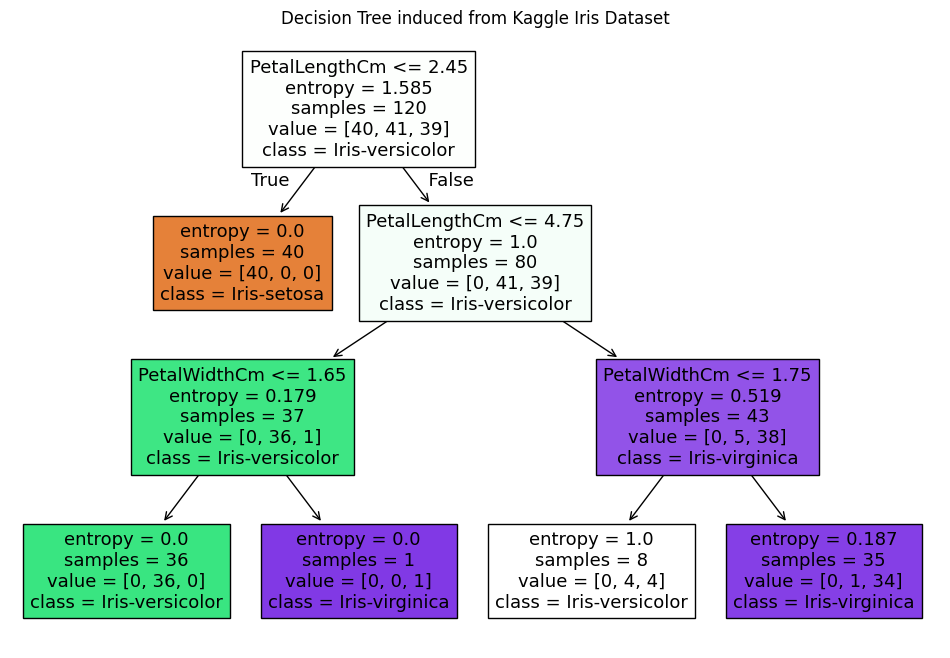

In [ ]:
# Visualize the Decision Tree trained on Kaggle dataset
plt.figure(figsize=(12, 8))
plot_tree(clf_k, feature_names=list(X_k.columns), class_names=list(y_k.unique()), filled=True)
plt.title("Decision Tree induced from Kaggle Iris Dataset")
plt.show()